✅ Saved: roi_coordinates_with_cell_id.csv
      ROI_ID  Cell_ID
0          0        0
88        22        0
84        21        0
80        20        0
76        19        0
...      ...      ...
1928     482       19
1924     481       19
2000     500       19
1960     490       19
2004     501       19

[502 rows x 2 columns]


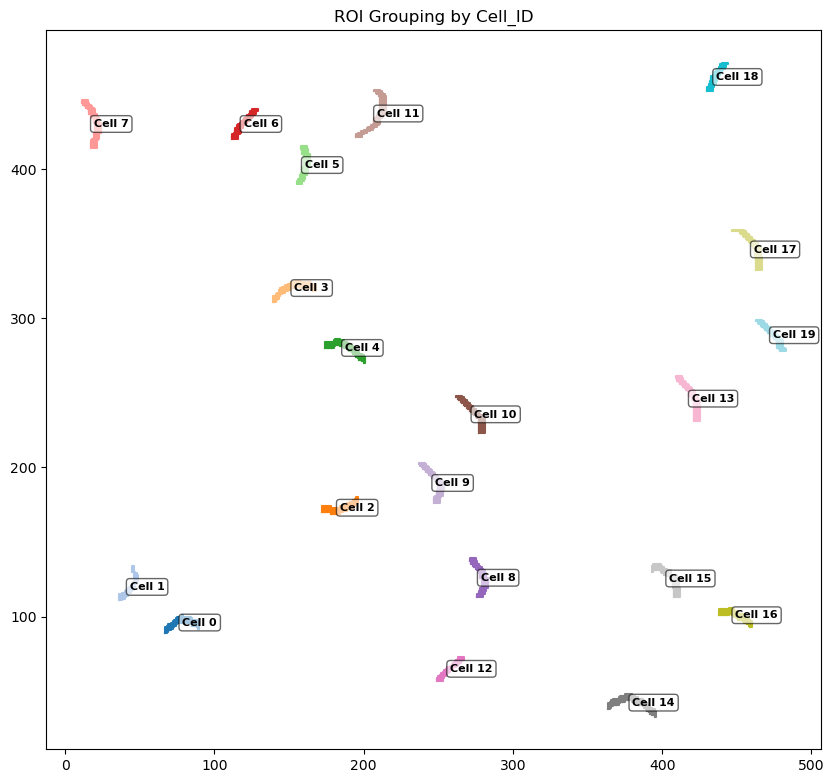

In [1]:
import pandas as pd
import numpy as np
import os
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from pathlib import Path
from scipy.spatial.distance import cdist

# --- Parameters ---
distance_threshold = 5  # pixels

# --- Load ROI coordinates ---
df = pd.read_csv("all_roi_coordinates.csv")  # Replace with your file
# Ensure columns: 'Label', 'X', 'Y'
df['ROI_ID'] = df['Label'].str.extract(r'ROI_(\d+)').astype(int)

# --- Step 1: Group points by ROI ---
roi_points = {roi: group[['X', 'Y']].values for roi, group in df.groupby('ROI_ID')}


# --- Step 2: Build proximity graph ---
G = nx.Graph()

roi_ids = list(roi_points.keys())
G.add_nodes_from(roi_ids)

for i, roi_a in enumerate(roi_ids):
    for j in range(i + 1, len(roi_ids)):
        roi_b = roi_ids[j]
        
        dist_matrix = cdist(roi_points[roi_a], roi_points[roi_b])
        min_dist = np.min(dist_matrix)
        
        if min_dist < distance_threshold:
            G.add_edge(roi_a, roi_b)

# --- Step 3: Assign cell IDs from connected components ---
roi_to_cell = {}
for cell_id, component in enumerate(nx.connected_components(G)):
    for roi_id in component:
        roi_to_cell[roi_id] = cell_id

# --- Step 4: Merge back into original dataframe ---
df['ROI_ID'] = df['ROI_ID'].astype(int)
df['Cell_ID'] = df['ROI_ID'].map(roi_to_cell)

# --- Save grouped result ---
df.to_csv("roi_coordinates_with_cell_id.csv", index=False)

print("✅ Saved: roi_coordinates_with_cell_id.csv")
print(df[['ROI_ID', 'Cell_ID']].drop_duplicates().sort_values('Cell_ID'))

# --- Load the ROI coordinate data ---
df = pd.read_csv("roi_coordinates_with_cell_id.csv")  # Output from previous step

# --- Plot setup ---
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_aspect('equal')
ax.set_title("ROI Grouping by Cell_ID")

# --- Colormap for cells ---
unique_cells = df['Cell_ID'].unique()
colors = cm.get_cmap('tab20', len(unique_cells))

# --- Draw each ROI ---
for roi_id, group in df.groupby('ROI_ID'):
    cell_id = group['Cell_ID'].iloc[0]
    color = colors(cell_id)

    x = group['X'].values
    y = group['Y'].values

    # Close the loop for polygon display
    x = np.append(x, x[0])
    y = np.append(y, y[0])

    ax.plot(x, y, label=f"ROI {roi_id}", color=color)

# # --- Optional: Label ROIs ---
# for roi_id, group in df.groupby('ROI_ID'):
#     x_mean = group['X'].mean()
#     y_mean = group['Y'].mean()
#     ax.text(x_mean, y_mean, str(roi_id), fontsize=8, ha='center', va='center')

# # --- Legend (optional) ---
# ax.legend(loc='upper right', fontsize=6)

# plt.xlabel("X (pixels)")
# plt.ylabel("Y (pixels)")
# plt.tight_layout()

# --- Label each Cell_ID at its centroid ---
for cell_id, group in df.groupby('Cell_ID'):
    x_center = group['X'].mean()
    y_center = group['Y'].mean()
    ax.text(
        x_center, y_center, f"Cell {cell_id}",
        fontsize=8, fontweight='bold', ha='left', va='center',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", lw=1, alpha=0.6)
    )

plt.savefig("roi_cell_map.png", dpi=300)
plt.show()


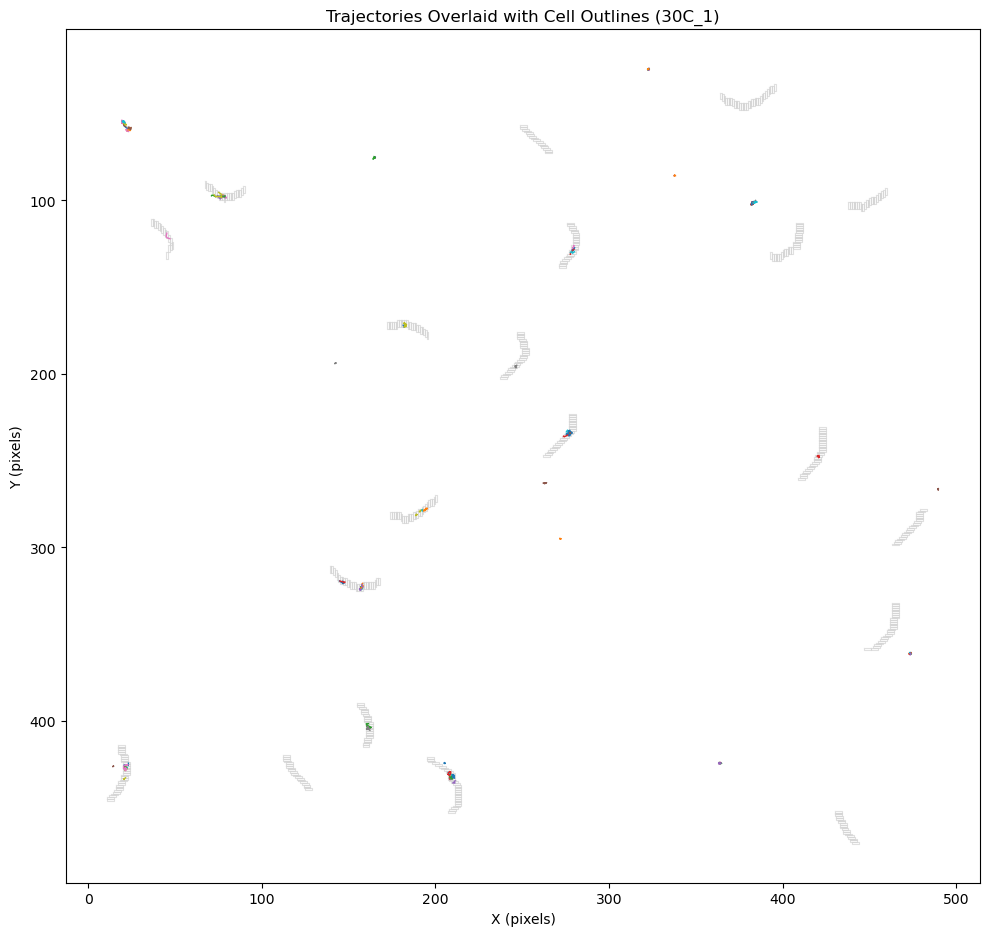

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import trackpy as tp
import numpy as np

# --- Load Trajectory Data ---
df_traj = pd.read_csv("30C_1_AfterActivation_07142025.csv")
R_squared_threshold = 0.80

qualified_sm = df_traj[
    (df_traj['classification'] == 'single molecule') &
    (df_traj['R²'] >= R_squared_threshold)
]

# --- Load ROI Shape Outlines ---
df_roi = pd.read_csv("roi_coordinates_with_cell_id.csv")

# --- Plot Setup ---
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_aspect('equal')
ax.set_title(f"Trajectories Overlaid with Cell Outlines (30C_1)")

# --- Draw each cell outline (light gray) ---
for roi_id, group in df_roi.groupby('ROI_ID'):
    x = group['X'].values
    y = group['Y'].values
    x = np.append(x, x[0])
    y = np.append(y, y[0])
    ax.plot(x, y, color='lightgray', linewidth=0.8, alpha=0.7)

# --- Plot Trajectories ---
if not qualified_sm.empty:
    tp.plot_traj(
        qualified_sm, ax=ax, label=False,
        linewidth=1.2, marker='o', markersize=2, color='blue'
    )
else:
    print(f"No single molecule trajectories")

# --- Final Touches ---
ax.set_xlabel("X (pixels)")
ax.set_ylabel("Y (pixels)")
plt.tight_layout()
plt.savefig("enhanced_trajectories_with_outlines.png", dpi=300)
plt.show()

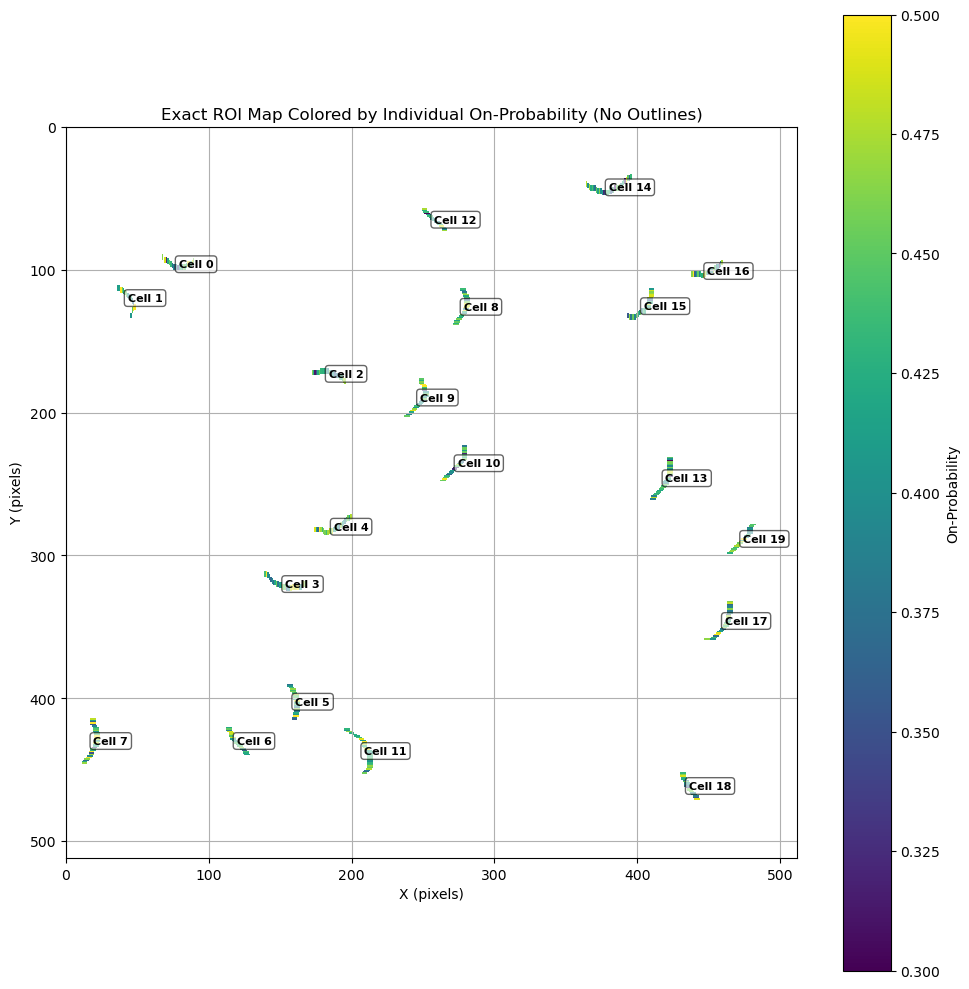

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import matplotlib.cm as cm

# --- Load Data ---
# Replace with your actual file paths if needed
roi_df = pd.read_csv("roi_coordinates_with_cell_id.csv")
on_prob_df = pd.read_csv("On_Probability_Summary.csv")

# --- Data Cleanup ---
roi_df['ROI_ID'] = pd.to_numeric(roi_df['ROI_ID'], errors='coerce')
on_prob_df['ROI'] = pd.to_numeric(on_prob_df['ROI'], errors='coerce')

# --- Merge On_Probability into ROI data ---
merged_df = pd.merge(roi_df, on_prob_df, left_on="ROI_ID", right_on="ROI")

# --- Clip to plotting window to avoid outliers ---
x_min, x_max = 0, 512
y_min, y_max = 0, 512
plot_df = merged_df[
    (merged_df['X'] >= x_min) & (merged_df['X'] <= x_max) &
    (merged_df['Y'] >= y_min) & (merged_df['Y'] <= y_max)
]

# --- Group ROI polygons ---
roi_polygons = (
    plot_df.groupby('ROI_ID')[['X', 'Y']]
    .apply(lambda df: [tuple(xy) for xy in df.values])
    .to_dict()
)
roi_prob_map = plot_df.groupby('ROI_ID')['On_Probability'].first()

# Replot without the black edge color on ROI polygons

fig, ax = plt.subplots(figsize=(10, 10))
ax.set_aspect('equal')
ax.set_title("Exact ROI Map Colored by Individual On-Probability (No Outlines)")

# Same normalization and colormap
#norm = plt.Normalize(vmin=roi_prob_map.min(), vmax=roi_prob_map.max())
norm = plt.Normalize(vmin=0.3, vmax=0.5)
cmap = cm.viridis

# Draw ROIs without black edges
for roi_id, polygon_coords in roi_polygons.items():
    color = cmap(norm(roi_prob_map[roi_id]))
    patch = Polygon(polygon_coords, closed=True, facecolor=color, edgecolor='none')
    ax.add_patch(patch)

# Cell labels remain
for cell_id, group in plot_df.groupby('Cell_ID'):
    x_center = group['X'].mean()
    y_center = group['Y'].mean()
    ax.text(
        x_center, y_center, f"Cell {cell_id}",
        fontsize=8, fontweight='bold', ha='left', va='center',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="black", lw=1, alpha=0.6)
    )

# Colorbar
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label("On-Probability")

# Axes settings
ax.set_xlim(x_min, x_max)
ax.set_ylim(y_max, y_min)
ax.set_xlabel("X (pixels)")
ax.set_ylabel("Y (pixels)")
ax.grid(True)
plt.tight_layout()
plt.show()



In [4]:
import os

# Create output folder
output_dir = "Heatmap_of_binding"
os.makedirs(output_dir, exist_ok=True)

# Normalize once for consistent colormap scaling across all plots
#norm = plt.Normalize(vmin=roi_prob_map.min(), vmax=roi_prob_map.max())
norm = plt.Normalize(vmin=0.3, vmax=0.5)
cmap = cm.viridis

# Plot and save each cell separately
for cell_id, cell_group in plot_df.groupby('Cell_ID'):
    # Prepare cell-specific ROI polygon and probabilities
    roi_polygons_cell = (
        cell_group.groupby('ROI_ID')[['X', 'Y']]
        .apply(lambda df: [tuple(xy) for xy in df.values])
        .to_dict()
    )
    roi_prob_map_cell = cell_group.groupby('ROI_ID')['On_Probability'].first()

    # Get plot bounds
    padding = 10
    x0, x1 = cell_group['X'].min() - padding, cell_group['X'].max() + padding
    y0, y1 = cell_group['Y'].min() - padding, cell_group['Y'].max() + padding

    # Start plot
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.set_aspect('equal')
    ax.set_title(f"Cell {cell_id}")

    for roi_id, polygon_coords in roi_polygons_cell.items():
        color = cmap(norm(roi_prob_map_cell[roi_id]))
        patch = Polygon(polygon_coords, closed=True, facecolor=color, edgecolor='none')
        ax.add_patch(patch)

    # Colorbar
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax)
    cbar.set_label("On-Probability")

    ax.set_xlim(x0, x1)
    ax.set_ylim(y1, y0)  # Invert y-axis
    ax.set_xlabel("X (pixels)")
    ax.set_ylabel("Y (pixels)")
    ax.grid(False)
    plt.tight_layout()

    # Save PNG without cell label
    filename = os.path.join(output_dir, f"Cell_{cell_id}_heatmap.png")
    plt.savefig(filename, dpi=300)
    plt.close()

output_dir

import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
import matplotlib.cm as cm
from matplotlib.backends.backend_pdf import PdfPages
import os

# Reload input files
roi_df = pd.read_csv("roi_coordinates_with_cell_id.csv")
on_prob_df = pd.read_csv("On_Probability_Summary.csv")

# Cleanup
roi_df['ROI_ID'] = pd.to_numeric(roi_df['ROI_ID'], errors='coerce')
on_prob_df['ROI'] = pd.to_numeric(on_prob_df['ROI'], errors='coerce')

# Merge
merged_df = pd.merge(roi_df, on_prob_df, left_on="ROI_ID", right_on="ROI")

# Clip to image bounds
x_min, x_max = 0, 512
y_min, y_max = 0, 512
plot_df = merged_df[
    (merged_df['X'] >= x_min) & (merged_df['X'] <= x_max) &
    (merged_df['Y'] >= y_min) & (merged_df['Y'] <= y_max)
]

# Output folder
output_dir = "Heatmap_of_binding"
os.makedirs(output_dir, exist_ok=True)

# Colormap normalization from 0.3 to 0.5
norm = plt.Normalize(vmin=0.3, vmax=0.5)
cmap = cm.viridis

# Create PDF
pdf_path = os.path.join(output_dir, "All_Cells_Heatmaps.pdf")
with PdfPages(pdf_path) as pdf:
    for cell_id, cell_group in plot_df.groupby('Cell_ID'):
        roi_polygons_cell = (
            cell_group.groupby('ROI_ID')[['X', 'Y']]
            .apply(lambda df: [tuple(xy) for xy in df.values])
            .to_dict()
        )
        roi_prob_map_cell = cell_group.groupby('ROI_ID')['On_Probability'].first()

        padding = 10
        x0, x1 = cell_group['X'].min() - padding, cell_group['X'].max() + padding
        y0, y1 = cell_group['Y'].min() - padding, cell_group['Y'].max() + padding

        fig, ax = plt.subplots(figsize=(6, 6))
        ax.set_aspect('equal')
        ax.set_title(f"Cell {cell_id}")

        for roi_id, polygon_coords in roi_polygons_cell.items():
            color = cmap(norm(roi_prob_map_cell[roi_id]))
            patch = Polygon(polygon_coords, closed=True, facecolor=color, edgecolor='none')
            ax.add_patch(patch)

        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, fraction=0.05, pad=0.03)
        cbar.set_label("On-Probability", fontsize=12)
        cbar.ax.tick_params(labelsize=10)

        ax.set_xlim(x0, x1)
        ax.set_ylim(y1, y0)
        ax.set_xlabel("X (pixels)")
        ax.set_ylabel("Y (pixels)")
        ax.grid(False)
        plt.tight_layout()
        pdf.savefig(fig)
        plt.close(fig)

pdf_path


'Heatmap_of_binding/All_Cells_Heatmaps.pdf'

In [5]:
import pandas as pd
from pathlib import Path

# --- Step 1: Load ROI coordinates with Cell_ID ---
df = pd.read_csv("roi_coordinates_with_cell_id.csv")

# Compute centroid of each ROI
roi_centroids = df.groupby("ROI_ID")[["X", "Y"]].mean().reset_index()
roi_centroids["Cell_ID"] = df.groupby("ROI_ID")["Cell_ID"].first().values

# --- Step 2: Load intensity profiles ---
intensity_dir = Path(".")  # Folder containing ROI_###_ZProfile.txt
profile_data = []

for file_path in intensity_dir.glob("ROI_*_ZProfile.txt"):
    try:
        roi_id = int(file_path.stem.split('_')[1])
    except Exception as e:
        print(f"Skipping {file_path.name}: {e}")
        continue

    profile = pd.read_csv(file_path, sep='\t', header=None, names=["Frame", "Intensity"])
    profile["ROI_ID"] = roi_id
    profile_data.append(profile)

if not profile_data:
    raise ValueError("❌ No valid intensity profiles found.")

intensity_df = pd.concat(profile_data, ignore_index=True)

# --- Step 3: Merge intensity with ROI centroid and Cell_ID ---
intensity_df = intensity_df.merge(roi_centroids, on="ROI_ID", how="left")

# --- Step 4: Assign Pole Labels Based on Intensity Profile ---
pole_labels = []

for cell_id, group in intensity_df.groupby("Cell_ID"):
    # Step 4.1: Compute mean intensity per ROI
    roi_means = group.groupby("ROI_ID")["Intensity"].mean().reset_index(name="MeanIntensity")
    
    # Step 4.2: Get ROI positions
    roi_positions = group.groupby("ROI_ID")[["X", "Y"]].first().reset_index()
    roi_positions["Cell_ID"] = cell_id

    # Step 4.3: Merge to get full per-ROI metadata
    roi_meta = roi_positions.merge(roi_means, on="ROI_ID").sort_values("X")  # or sort by Y if vertical

    # Step 4.4: Find poles by comparing mean intensity
    first3 = roi_meta.head(3)
    last3 = roi_meta.tail(3)
    mean_first3 = first3["MeanIntensity"].mean()
    mean_last3 = last3["MeanIntensity"].mean()

    if mean_first3 > mean_last3:
        stalk_pole = first3["ROI_ID"].tolist()
        swarmer_pole = last3["ROI_ID"].tolist()
    else:
        stalk_pole = last3["ROI_ID"].tolist()
        swarmer_pole = first3["ROI_ID"].tolist()

    # Step 4.5: Label ROIs
    for roi_id in roi_meta["ROI_ID"]:
        if roi_id in stalk_pole:
            label = "stalk"
        elif roi_id in swarmer_pole:
            label = "swarmer"
        else:
            label = "mid"

        pole_labels.append({
            "ROI_ID": roi_id,
            "Cell_ID": cell_id,
            "PoleLabel": label
        })

# --- Step 5: Save results ---
pole_df = pd.DataFrame(pole_labels)

# Add back positional and intensity data for context
roi_full_info = roi_centroids.merge(pole_df, on=["ROI_ID", "Cell_ID"])
intensity_df = intensity_df.merge(pole_df, on=["ROI_ID", "Cell_ID"], how="left")

# Save full per-frame intensity data with pole labels
intensity_df.to_csv("roi_intensity_with_pole_labels.csv", index=False)
roi_full_info.to_csv("roi_with_pole_labels.csv", index=False)

print("✅ Saved: roi_with_pole_labels.csv and roi_intensity_with_pole_labels.csv")
print(roi_full_info[["Cell_ID", "ROI_ID", "PoleLabel"]].value_counts().sort_index())


✅ Saved: roi_with_pole_labels.csv and roi_intensity_with_pole_labels.csv
Cell_ID  ROI_ID  PoleLabel
0        0       stalk        1
         1       stalk        1
         2       mid          1
         3       mid          1
         4       mid          1
                             ..
19       497     mid          1
         498     mid          1
         499     swarmer      1
         500     swarmer      1
         501     swarmer      1
Length: 502, dtype: int64


In [6]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy.ndimage import uniform_filter1d

# --- Load ROI centroid and Cell_ID ---
df = pd.read_csv("roi_coordinates_with_cell_id.csv")
roi_centroids = df.groupby("ROI_ID")[["X", "Y"]].mean().reset_index()
roi_centroids["Cell_ID"] = df.groupby("ROI_ID")["Cell_ID"].first().values

# --- Load intensity profiles ---
intensity_dir = Path(".")
profile_data = []

for file_path in intensity_dir.glob("ROI_*_ZProfile.txt"):
    try:
        roi_id = int(file_path.stem.split('_')[1])
        profile = pd.read_csv(file_path, sep='\t', header=None, names=["Frame", "Intensity"])
        profile["ROI_ID"] = roi_id
        profile_data.append(profile)
    except Exception as e:
        print(f"Skipping {file_path.name}: {e}")

if not profile_data:
    raise ValueError("❌ No valid intensity profiles found.")

intensity_df = pd.concat(profile_data, ignore_index=True)
intensity_df = intensity_df.merge(roi_centroids, on="ROI_ID", how="left")

# --- Pole labeling based on intensity of edge ROIs ---
labeled_rois = []
for cell_id, group in intensity_df.groupby("Cell_ID"):
    unique_rois = group["ROI_ID"].unique()
    roi_avg_intensity = {
        roi: intensity_df[intensity_df["ROI_ID"] == roi]["Intensity"].mean()
        for roi in unique_rois
    }
    sorted_rois = sorted(unique_rois, key=lambda r: roi_centroids.loc[roi_centroids["ROI_ID"] == r, "X"].values[0])
    stalk_candidates = sorted_rois[:3]
    swarmer_candidates = sorted_rois[-3:]

    stalk_avg = np.mean([roi_avg_intensity[r] for r in stalk_candidates])
    swarmer_avg = np.mean([roi_avg_intensity[r] for r in swarmer_candidates])

    if stalk_avg > swarmer_avg:
        stalk_rois, swarmer_rois = stalk_candidates, swarmer_candidates
    else:
        stalk_rois, swarmer_rois = swarmer_candidates, stalk_candidates

    for roi in unique_rois:
        if roi in stalk_rois:
            pole = "stalk"
        elif roi in swarmer_rois:
            pole = "swarmer"
        else:
            pole = "middle"
        labeled_rois.append({"ROI_ID": roi, "Cell_ID": cell_id, "PoleLabel": pole})

pole_df = pd.DataFrame(labeled_rois)
roi_centroids = roi_centroids.merge(pole_df, on=["ROI_ID", "Cell_ID"], how="left")
intensity_df = intensity_df.merge(pole_df, on=["ROI_ID", "Cell_ID"], how="left")

# --- Transition detection logic from MATLAB ---
def detect_binding_events(signal, smoothing=20, window=60, std_multiplier=-0.1, min_duration=10):
    smoothed = uniform_filter1d(signal, size=smoothing)
    local_mean = uniform_filter1d(smoothed, size=window)
    local_std = pd.Series(smoothed).rolling(window, center=True).std().bfill().ffill()
    threshold = local_mean + std_multiplier * local_std.values
    is_bound = smoothed > threshold
    transitions = np.diff(is_bound.astype(int))
    binding = np.where(transitions == 1)[0]
    unbinding = np.where(transitions == -1)[0]

    # Align binding/unbinding
    if len(binding) and len(unbinding):
        if unbinding[0] < binding[0]:
            unbinding = unbinding[1:]
        if len(binding) > len(unbinding):
            binding = binding[:len(unbinding)]

    # Filter short events
    on_times = unbinding - binding
    valid = on_times >= min_duration
    return binding[valid], unbinding[valid]

# --- Step 1: Extract first binding frame per ROI ---
first_binding_frames = []

for roi_id, group in intensity_df.groupby("ROI_ID"):
    trace = group.sort_values("Frame")["Intensity"].values
    frames = group.sort_values("Frame")["Frame"].values
    bindings, unbindings = detect_binding_events(trace)
    if len(bindings):
        first_frame = frames[bindings[0]]
        x = group["X"].iloc[0]
        y = group["Y"].iloc[0]
        cell_id = group["Cell_ID"].iloc[0]
        label = group["PoleLabel"].iloc[0]
        first_binding_frames.append({
            "ROI_ID": roi_id,
            "Cell_ID": cell_id,
            "BindingFrame": first_frame,
            "X": x,
            "Y": y,
            "PoleLabel": label
        })

binding_df = pd.DataFrame(first_binding_frames)

# --- Step 2: Flow vector computation based on binding frame order ---
flow_data = []
for cell_id, group in binding_df.groupby("Cell_ID"):
    group = group.sort_values("BindingFrame").reset_index(drop=True)

    stalk = group[group["PoleLabel"] == "stalk"][["X", "Y"]].mean()
    swarmer = group[group["PoleLabel"] == "swarmer"][["X", "Y"]].mean()
    if stalk.isnull().any() or swarmer.isnull().any():
        continue

    axis_vec = np.array([swarmer["X"] - stalk["X"], swarmer["Y"] - stalk["Y"]])
    axis_unit = axis_vec / np.linalg.norm(axis_vec)

    for i in range(len(group) - 1):
        r1 = group.iloc[i]
        r2 = group.iloc[i + 1]

        dx = r2["X"] - r1["X"]
        dy = r2["Y"] - r1["Y"]
        dt = r2["BindingFrame"] - r1["BindingFrame"]
        speed = np.sqrt(dx**2 + dy**2) / dt if dt != 0 else 0
        angle = np.degrees(np.arctan2(dy, dx))
        movement = np.array([dx, dy])
        directional_speed = np.dot(movement, axis_unit) / dt if dt != 0 else 0

        flow_data.append({
            "Cell_ID": cell_id,
            "From_ROI": r1["ROI_ID"],
            "To_ROI": r2["ROI_ID"],
            "dx": dx,
            "dy": dy,
            "dt": dt,
            "speed": speed,
            "angle_deg": angle,
            "directional_speed": directional_speed
        })

flow_df = pd.DataFrame(flow_data)

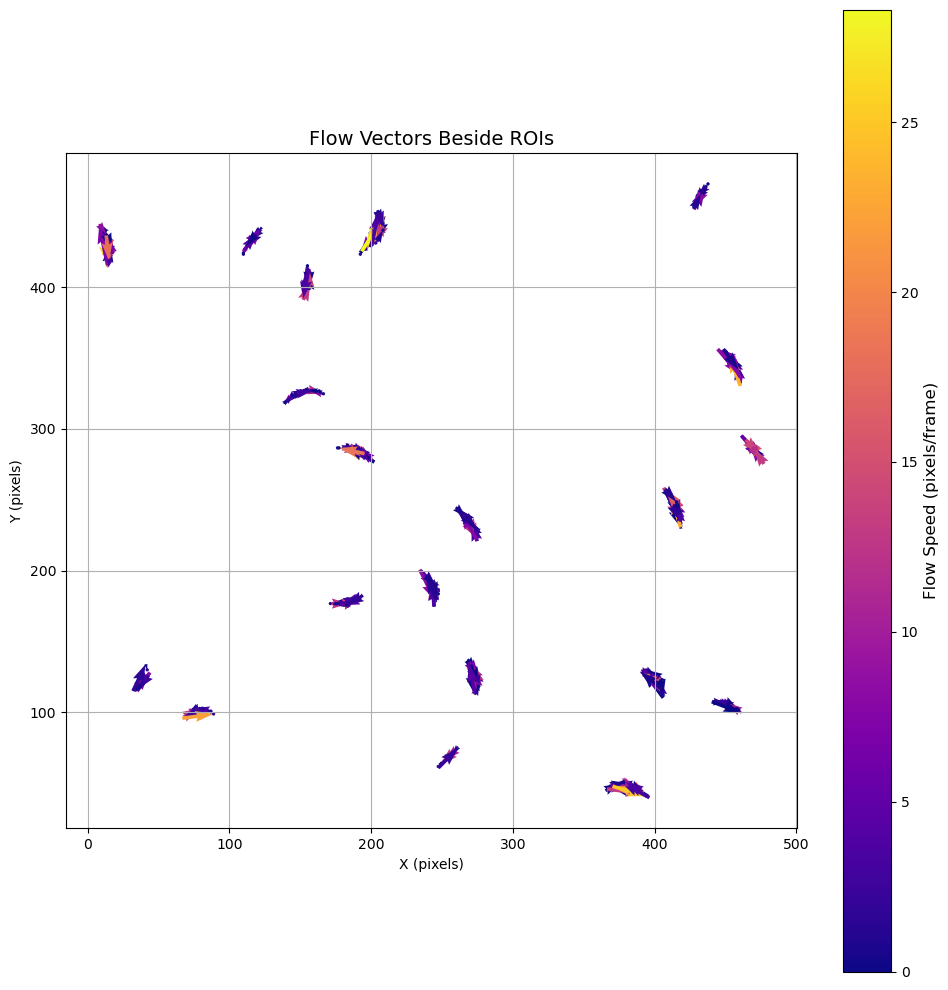

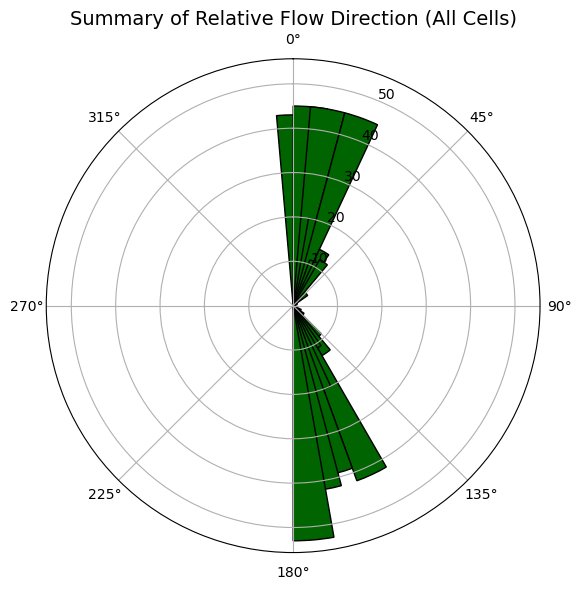

✅ Done. Saved flow vector plot beside cells and summary rose plot.
✅ Saved individual polar plots for 20 cells to: relative_direction_plots/


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import os

# Load data
flow_df = pd.read_csv("flow_vectors_with_directionality.csv")
peak_info = pd.read_csv("roi_with_pole_labels.csv")
peak_info = peak_info.rename(columns={"X": "X_peak", "Y": "Y_peak"})

# Merge peak info for origin of vectors
flow_df = flow_df.merge(
    peak_info[["ROI_ID", "X_peak", "Y_peak"]],
    left_on="From_ROI", right_on="ROI_ID", how="left"
).rename(columns={"X_peak": "X_peak_from", "Y_peak": "Y_peak_from"}).drop(columns=["ROI_ID"])

# --- Recompute relative angles ---
def unit_vector(vec):
    norm = np.linalg.norm(vec)
    return vec / norm if norm != 0 else vec

def angle_between(v1, v2):
    v1_u = unit_vector(v1)
    v2_u = unit_vector(v2)
    dot = np.clip(np.dot(v1_u, v2_u), -1.0, 1.0)
    angle = np.arccos(dot)
    return np.degrees(angle)

flow_df['relative_angle_deg'] = np.nan
flow_df['x_offset'] = np.nan
flow_df['y_offset'] = np.nan

# Offset amount for arrows
offset_distance = 5

for cell_id, group in flow_df.groupby("Cell_ID"):
    centroids = peak_info[peak_info["Cell_ID"] == cell_id][["X_peak", "Y_peak"]].values
    if len(centroids) < 2:
        continue
    x_span = centroids[:, 0].max() - centroids[:, 0].min()
    y_span = centroids[:, 1].max() - centroids[:, 1].min()
    if x_span >= y_span:
        left_idx = centroids[:, 0].argmin()
        right_idx = centroids[:, 0].argmax()
    else:
        left_idx = centroids[:, 1].argmin()
        right_idx = centroids[:, 1].argmax()
    baseline = centroids[right_idx] - centroids[left_idx]
    axis_unit = unit_vector(baseline)
    perp_unit = np.array([-axis_unit[1], axis_unit[0]])  # perpendicular

    for idx in group.index:
        vec = np.array([flow_df.loc[idx, 'dx'], flow_df.loc[idx, 'dy']])
        angle = angle_between(baseline, vec)
        flow_df.at[idx, 'relative_angle_deg'] = angle

        # Apply perpendicular offset
        flow_df.at[idx, 'x_offset'] = flow_df.loc[idx, 'X_peak_from'] + offset_distance * perp_unit[0]
        flow_df.at[idx, 'y_offset'] = flow_df.loc[idx, 'Y_peak_from'] + offset_distance * perp_unit[1]

# --- Quiver Plot (Arrows beside cells) ---
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_aspect('equal')
ax.set_title("Flow Vectors Beside ROIs", fontsize=14)
ax.set_xlabel("X (pixels)")
ax.set_ylabel("Y (pixels)")

cmap = cm.plasma
norm = plt.Normalize(flow_df['speed'].min(), flow_df['speed'].max())

for _, row in flow_df.iterrows():
    x0, y0 = row['x_offset'], row['y_offset']
    dx, dy = row['dx'], row['dy']
    color = cmap(norm(row['speed']))
    ax.quiver(x0, y0, dx, dy, angles='xy', scale_units='xy', scale=1, color=color, width=0.005)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Flow Speed (pixels/frame)', fontsize=12)

plt.grid(True)
plt.tight_layout()
plt.savefig("flow_vector_map_cells.png", dpi=300)
plt.show()

# --- Summary rose plot of all relative angles ---
relative_angles_deg = flow_df["relative_angle_deg"].dropna() % 360
relative_angles_rad = np.deg2rad(relative_angles_deg)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(8, 6))
n_bins = 36
counts, bins = np.histogram(relative_angles_rad, bins=n_bins)
width = (2 * np.pi) / n_bins
ax.bar(bins[:-1], counts, width=width, bottom=0.0, color='darkgreen', edgecolor='black')

ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)
ax.set_title("Summary of Relative Flow Direction (All Cells)", fontsize=14)
plt.tight_layout()
plt.savefig("summary_relative_direction_roseplot.png", dpi=300)
plt.show()

# Save updated DataFrame
flow_df.to_csv("flow_vectors_with_directionality_and_relative_angle.csv", index=False)
print("✅ Done. Saved flow vector plot beside cells and summary rose plot.")

# --- Individual rose plots per cell using relative angles ---
per_cell_dir = "relative_direction_plots"
os.makedirs(per_cell_dir, exist_ok=True)

n_bins = 36
bin_width = 2 * np.pi / n_bins

for cell_id, group in flow_df.groupby("Cell_ID"):
    rel_angles_deg = group["relative_angle_deg"].dropna() % 360
    if len(rel_angles_deg) == 0:
        continue  # Skip cells with no data

    rel_angles_rad = np.deg2rad(rel_angles_deg)

    fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(6, 5))
    counts, bins = np.histogram(rel_angles_rad, bins=n_bins)

    ax.bar(bins[:-1], counts, width=bin_width, color='darkgreen', edgecolor='black')
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_title(f"Cell {cell_id} Relative Flow Direction", fontsize=12)

    plt.tight_layout()
    plt.savefig(f"{per_cell_dir}/cell_{cell_id}_relative_direction.png", dpi=300)
    plt.close()

print(f"✅ Saved individual polar plots for {flow_df['Cell_ID'].nunique()} cells to: {per_cell_dir}/")



In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.backends.backend_pdf import PdfPages
import os
from pathlib import Path
from scipy.ndimage import uniform_filter1d

# ----------------------- Load Required Data -----------------------
flow_df = pd.read_csv("flow_vectors_with_directionality.csv")
intensity_df = pd.read_csv("roi_coordinates_with_cell_id.csv")

# Load intensity profiles from individual text files
intensity_dir = Path("")
profile_data = []

for file_path in intensity_dir.glob("ROI_*_ZProfile.txt"):
    try:
        roi_id = int(file_path.stem.split('_')[1])
        profile = pd.read_csv(file_path, sep='\t', header=None, names=["Frame", "Intensity"])
        profile["ROI_ID"] = roi_id
        profile_data.append(profile)
    except Exception as e:
        continue

if not profile_data:
    raise ValueError("❌ No valid intensity profiles found.")

full_profile_df = pd.concat(profile_data, ignore_index=True)
roi_centroids = intensity_df.groupby("ROI_ID")[["X", "Y"]].mean().reset_index()
roi_centroids["Cell_ID"] = intensity_df.groupby("ROI_ID")["Cell_ID"].first().values
full_profile_df = full_profile_df.merge(roi_centroids, on="ROI_ID", how="left")

# ----------------------- Compute Relative Polar Intensity -----------------------
intensity_summary = []

for roi_id, group in full_profile_df.groupby("ROI_ID"):
    trace = group.sort_values("Frame")["Intensity"].values
    baseline = np.percentile(trace, 20)
    peak = np.max(trace)
    rel_intensity = peak - baseline
    intensity_summary.append({"ROI_ID": roi_id, "Relative_Polar_Intensity": rel_intensity})

intensity_summary_df = pd.DataFrame(intensity_summary)

# Merge with peak_info
peak_info = roi_centroids.merge(intensity_summary_df, on="ROI_ID", how="left")

# Merge origin info into flow_df
flow_df = flow_df.merge(
    peak_info[["ROI_ID", "X", "Y", "Relative_Polar_Intensity"]],
    left_on="From_ROI", right_on="ROI_ID", how="left"
).rename(columns={"X": "X_peak_from", "Y": "Y_peak_from"}).drop(columns=["ROI_ID"])

# ----------------------- Compute Relative Angles and Offsets -----------------------
def unit_vector(vec):
    norm = np.linalg.norm(vec)
    return vec / norm if norm != 0 else vec

def angle_between(v1, v2):
    v1_u = unit_vector(v1)
    v2_u = unit_vector(v2)
    dot = np.clip(np.dot(v1_u, v2_u), -1.0, 1.0)
    angle = np.arccos(dot)
    return np.degrees(angle)

flow_df['relative_angle_deg'] = np.nan
flow_df['x_offset'] = np.nan
flow_df['y_offset'] = np.nan

offset_distance = 5
for cell_id, group in flow_df.groupby("Cell_ID"):
    centroids = peak_info[peak_info["Cell_ID"] == cell_id][["X", "Y"]].values
    if len(centroids) < 2:
        continue
    x_span = centroids[:, 0].max() - centroids[:, 0].min()
    y_span = centroids[:, 1].max() - centroids[:, 1].min()
    if x_span >= y_span:
        left_idx = centroids[:, 0].argmin()
        right_idx = centroids[:, 0].argmax()
    else:
        left_idx = centroids[:, 1].argmin()
        right_idx = centroids[:, 1].argmax()
    baseline = centroids[right_idx] - centroids[left_idx]
    axis_unit = unit_vector(baseline)
    perp_unit = np.array([-axis_unit[1], axis_unit[0]])

    for idx in group.index:
        vec = np.array([flow_df.loc[idx, 'dx'], flow_df.loc[idx, 'dy']])
        angle = angle_between(baseline, vec)
        flow_df.at[idx, 'relative_angle_deg'] = angle
        flow_df.at[idx, 'x_offset'] = flow_df.loc[idx, 'X_peak_from'] + offset_distance * perp_unit[0]
        flow_df.at[idx, 'y_offset'] = flow_df.loc[idx, 'Y_peak_from'] + offset_distance * perp_unit[1]

# ----------------------- Plot and Save Per Cell -----------------------
output_dir = "flow_vector_per_cell"
os.makedirs(output_dir, exist_ok=True)
pdf_path = os.path.join(output_dir, "All_Cells_VectorFlow.pdf")

norm = plt.Normalize(flow_df['speed'].min(), flow_df['speed'].max())
cmap = cm.magma_r  # lighter colors = faster speeds

min_size, max_size = 20, 300
intensity_min = flow_df['Relative_Polar_Intensity'].min()
intensity_max = flow_df['Relative_Polar_Intensity'].max()

with PdfPages(pdf_path) as pdf:
    for cell_id, group in flow_df.groupby("Cell_ID"):
        if group.empty:
            continue
        x0, x1 = group['x_offset'].min() - 5, group['x_offset'].max() + 5
        y0, y1 = group['y_offset'].min() - 5, group['y_offset'].max() + 5

        fig, ax = plt.subplots(figsize=(6, 6))
        ax.set_aspect('equal')
        ax.set_title(f"Cell {cell_id} Flow Vectors", fontsize=12)

        for _, row in group.iterrows():
            color = cmap(norm(row['speed']))
            ax.quiver(
                row['x_offset'], row['y_offset'],
                row['dx'], row['dy'],
                angles='xy', scale_units='xy', scale=5,
                color=color, width=0.006, headwidth=5, headlength=6
            )
            # Intensity circle
            size = min_size + (row['Relative_Polar_Intensity'] - intensity_min) / (intensity_max - intensity_min) * (max_size - min_size)
            ax.scatter(row['X_peak_from'], row['Y_peak_from'], s=size, color='blue', alpha=0.3, edgecolor='none')

        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, fraction=0.05, pad=0.03)
        cbar.set_label("Flow Speed (pixels/frame)", fontsize=10)

        ax.set_xlim(x0, x1)
        ax.set_ylim(y1, y0)
        ax.set_xlabel("X (pixels)")
        ax.set_ylabel("Y (pixels)")
        ax.grid(True)
        plt.tight_layout()

        png_path = os.path.join(output_dir, f"cell_{cell_id}_vector.png")
        plt.savefig(png_path, dpi=300)
        pdf.savefig(fig)
        plt.close(fig)

pdf_path

# Re-import required libraries due to session reset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.backends.backend_pdf import PdfPages
import os

# Reload data
flow_df = pd.read_csv("flow_vectors_with_directionality.csv")
peak_info = pd.read_csv("roi_with_pole_labels.csv")
peak_info = peak_info.rename(columns={"X": "X_peak", "Y": "Y_peak"})

# Merge origin info
flow_df = flow_df.merge(
    peak_info[["ROI_ID", "X_peak", "Y_peak"]],
    left_on="From_ROI", right_on="ROI_ID", how="left"
).rename(columns={"X_peak": "X_peak_from", "Y_peak": "Y_peak_from"}).drop(columns=["ROI_ID"])

# Compute relative angle and offset
def unit_vector(vec):
    norm = np.linalg.norm(vec)
    return vec / norm if norm != 0 else vec

def angle_between(v1, v2):
    v1_u = unit_vector(v1)
    v2_u = unit_vector(v2)
    dot = np.clip(np.dot(v1_u, v2_u), -1.0, 1.0)
    angle = np.arccos(dot)
    return np.degrees(angle)

flow_df['relative_angle_deg'] = np.nan
flow_df['x_offset'] = np.nan
flow_df['y_offset'] = np.nan

offset_distance = 5
for cell_id, group in flow_df.groupby("Cell_ID"):
    centroids = peak_info[peak_info["Cell_ID"] == cell_id][["X_peak", "Y_peak"]].values
    if len(centroids) < 2:
        continue
    x_span = centroids[:, 0].max() - centroids[:, 0].min()
    y_span = centroids[:, 1].max() - centroids[:, 1].min()
    if x_span >= y_span:
        left_idx = centroids[:, 0].argmin()
        right_idx = centroids[:, 0].argmax()
    else:
        left_idx = centroids[:, 1].argmin()
        right_idx = centroids[:, 1].argmax()
    baseline = centroids[right_idx] - centroids[left_idx]
    axis_unit = unit_vector(baseline)
    perp_unit = np.array([-axis_unit[1], axis_unit[0]])

    for idx in group.index:
        vec = np.array([flow_df.loc[idx, 'dx'], flow_df.loc[idx, 'dy']])
        angle = angle_between(baseline, vec)
        flow_df.at[idx, 'relative_angle_deg'] = angle
        flow_df.at[idx, 'x_offset'] = flow_df.loc[idx, 'X_peak_from'] + offset_distance * perp_unit[0]
        flow_df.at[idx, 'y_offset'] = flow_df.loc[idx, 'Y_peak_from'] + offset_distance * perp_unit[1]

# Save zoomed vector plots per cell
vector_dir = "flow_vector_per_cell"
os.makedirs(vector_dir, exist_ok=True)
pdf_path = os.path.join(vector_dir, "All_Cells_VectorFlow.pdf")

norm = plt.Normalize(flow_df['speed'].min(), flow_df['speed'].max())
cmap = cm.plasma

with PdfPages(pdf_path) as pdf:
    for cell_id, group in flow_df.groupby("Cell_ID"):
        if group.empty:
            continue
        x0, x1 = group['x_offset'].min() - 5, group['x_offset'].max() + 5
        y0, y1 = group['y_offset'].min() - 5, group['y_offset'].max() + 5

        fig, ax = plt.subplots(figsize=(6, 6))
        ax.set_aspect('equal')
        ax.set_title(f"Cell {cell_id} Flow Vectors", fontsize=12)

        for _, row in group.iterrows():
            color = cmap(norm(row['speed']))
            ax.quiver(
                row['x_offset'], row['y_offset'],
                row['dx'], row['dy'],
                angles='xy', scale_units='xy', scale=5,  # smaller arrows
                color=color, width=0.006, headwidth=5, headlength=6
            )

        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, fraction=0.05, pad=0.03)
        cbar.set_label("Flow Speed (pixels/frame)", fontsize=10)

        ax.set_xlim(x0, x1)
        ax.set_ylim(y1, y0)
        ax.set_xlabel("X (pixels)")
        ax.set_ylabel("Y (pixels)")
        ax.grid(True)
        plt.tight_layout()

        png_path = os.path.join(vector_dir, f"cell_{cell_id}_vector.png")
        plt.savefig(png_path, dpi=300)
        pdf.savefig(fig)
        plt.close(fig)

pdf_path

'flow_vector_per_cell/All_Cells_VectorFlow.pdf'

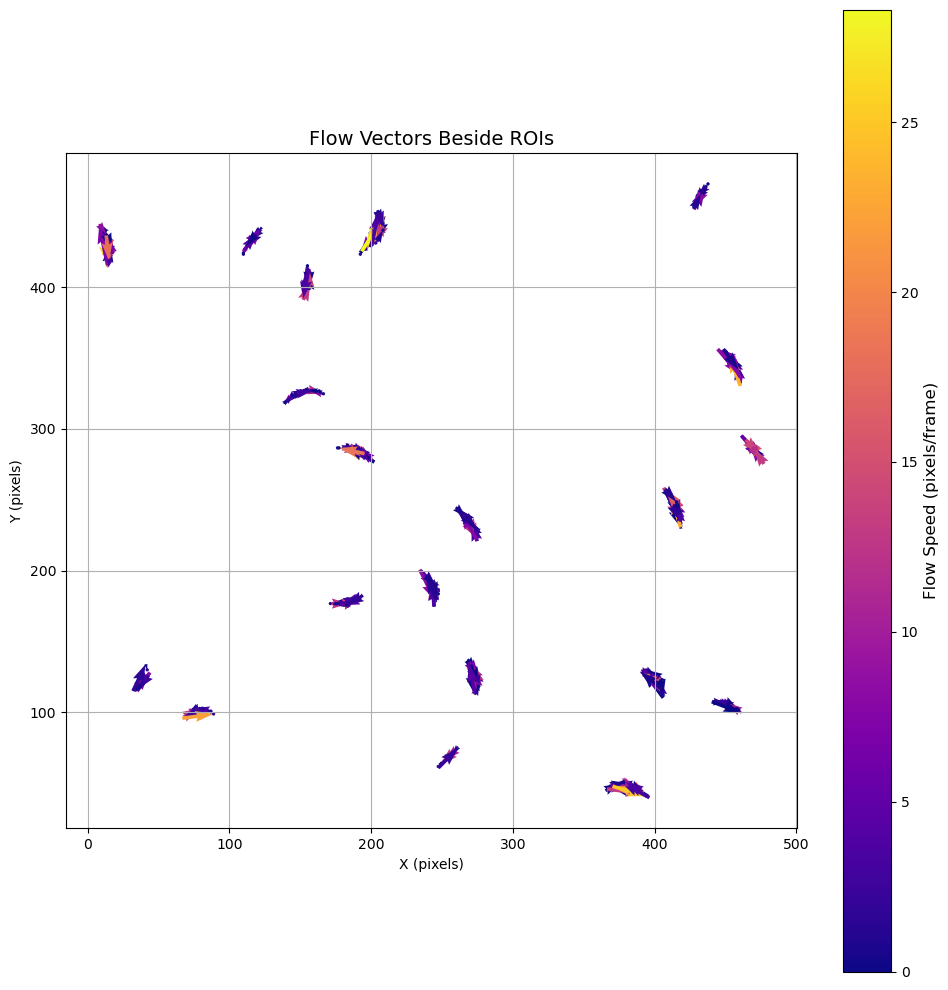

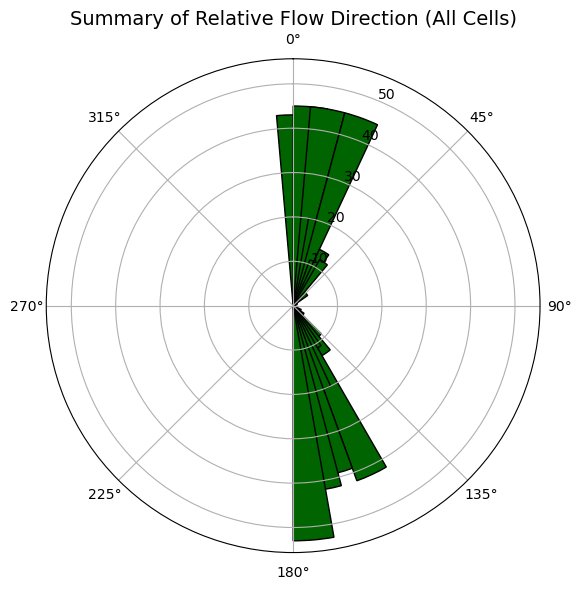

✅ Done. Saved flow vector plot beside cells and summary rose plot.
✅ Saved individual polar plots for 20 cells to: relative_direction_plots/


'flow_vector_per_cell/All_Cells_VectorFlow.pdf'

In [9]:
import pandas as pd
import numpy as np
from pathlib import Path
from scipy.ndimage import uniform_filter1d

# --- Load ROI centroid and Cell_ID ---
df = pd.read_csv("roi_coordinates_with_cell_id.csv")
roi_centroids = df.groupby("ROI_ID")[["X", "Y"]].mean().reset_index()
roi_centroids["Cell_ID"] = df.groupby("ROI_ID")["Cell_ID"].first().values

# --- Load intensity profiles ---
intensity_dir = Path(".")
profile_data = []

for file_path in intensity_dir.glob("ROI_*_ZProfile.txt"):
    try:
        roi_id = int(file_path.stem.split('_')[1])
        profile = pd.read_csv(file_path, sep='\t', header=None, names=["Frame", "Intensity"])
        profile["ROI_ID"] = roi_id
        profile_data.append(profile)
    except Exception as e:
        print(f"Skipping {file_path.name}: {e}")

if not profile_data:
    raise ValueError("❌ No valid intensity profiles found.")

intensity_df = pd.concat(profile_data, ignore_index=True)
intensity_df = intensity_df.merge(roi_centroids, on="ROI_ID", how="left")

# --- Pole labeling based on intensity of edge ROIs ---
labeled_rois = []
for cell_id, group in intensity_df.groupby("Cell_ID"):
    unique_rois = group["ROI_ID"].unique()
    roi_avg_intensity = {
        roi: intensity_df[intensity_df["ROI_ID"] == roi]["Intensity"].mean()
        for roi in unique_rois
    }
    sorted_rois = sorted(unique_rois, key=lambda r: roi_centroids.loc[roi_centroids["ROI_ID"] == r, "X"].values[0])
    stalk_candidates = sorted_rois[:3]
    swarmer_candidates = sorted_rois[-3:]

    stalk_avg = np.mean([roi_avg_intensity[r] for r in stalk_candidates])
    swarmer_avg = np.mean([roi_avg_intensity[r] for r in swarmer_candidates])

    if stalk_avg > swarmer_avg:
        stalk_rois, swarmer_rois = stalk_candidates, swarmer_candidates
    else:
        stalk_rois, swarmer_rois = swarmer_candidates, stalk_candidates

    for roi in unique_rois:
        if roi in stalk_rois:
            pole = "stalk"
        elif roi in swarmer_rois:
            pole = "swarmer"
        else:
            pole = "middle"
        labeled_rois.append({"ROI_ID": roi, "Cell_ID": cell_id, "PoleLabel": pole})

pole_df = pd.DataFrame(labeled_rois)
roi_centroids = roi_centroids.merge(pole_df, on=["ROI_ID", "Cell_ID"], how="left")
intensity_df = intensity_df.merge(pole_df, on=["ROI_ID", "Cell_ID"], how="left")

# --- Transition detection logic from MATLAB ---
def detect_binding_events(signal, smoothing=20, window=60, std_multiplier=-0.1, min_duration=10):
    smoothed = uniform_filter1d(signal, size=smoothing)
    local_mean = uniform_filter1d(smoothed, size=window)
    local_std = pd.Series(smoothed).rolling(window, center=True).std().bfill().ffill()
    threshold = local_mean + std_multiplier * local_std.values
    is_bound = smoothed > threshold
    transitions = np.diff(is_bound.astype(int))
    binding = np.where(transitions == 1)[0]
    unbinding = np.where(transitions == -1)[0]

    # Align binding/unbinding
    if len(binding) and len(unbinding):
        if unbinding[0] < binding[0]:
            unbinding = unbinding[1:]
        if len(binding) > len(unbinding):
            binding = binding[:len(unbinding)]

    # Filter short events
    on_times = unbinding - binding
    valid = on_times >= min_duration
    return binding[valid], unbinding[valid]

# --- Step 1: Extract first binding frame per ROI ---
first_binding_frames = []

for roi_id, group in intensity_df.groupby("ROI_ID"):
    trace = group.sort_values("Frame")["Intensity"].values
    frames = group.sort_values("Frame")["Frame"].values
    bindings, unbindings = detect_binding_events(trace)
    if len(bindings):
        first_frame = frames[bindings[0]]
        x = group["X"].iloc[0]
        y = group["Y"].iloc[0]
        cell_id = group["Cell_ID"].iloc[0]
        label = group["PoleLabel"].iloc[0]
        first_binding_frames.append({
            "ROI_ID": roi_id,
            "Cell_ID": cell_id,
            "BindingFrame": first_frame,
            "X": x,
            "Y": y,
            "PoleLabel": label
        })

binding_df = pd.DataFrame(first_binding_frames)

# --- Step 2: Flow vector computation based on binding frame order ---
flow_data = []
for cell_id, group in binding_df.groupby("Cell_ID"):
    group = group.sort_values("BindingFrame").reset_index(drop=True)

    stalk = group[group["PoleLabel"] == "stalk"][["X", "Y"]].mean()
    swarmer = group[group["PoleLabel"] == "swarmer"][["X", "Y"]].mean()
    if stalk.isnull().any() or swarmer.isnull().any():
        continue

    axis_vec = np.array([swarmer["X"] - stalk["X"], swarmer["Y"] - stalk["Y"]])
    axis_unit = axis_vec / np.linalg.norm(axis_vec)

    for i in range(len(group) - 1):
        r1 = group.iloc[i]
        r2 = group.iloc[i + 1]

        dx = r2["X"] - r1["X"]
        dy = r2["Y"] - r1["Y"]
        dt = r2["BindingFrame"] - r1["BindingFrame"]
        speed = np.sqrt(dx**2 + dy**2) / dt if dt != 0 else 0
        angle = np.degrees(np.arctan2(dy, dx))
        movement = np.array([dx, dy])
        directional_speed = np.dot(movement, axis_unit) / dt if dt != 0 else 0

        flow_data.append({
            "Cell_ID": cell_id,
            "From_ROI": r1["ROI_ID"],
            "To_ROI": r2["ROI_ID"],
            "dx": dx,
            "dy": dy,
            "dt": dt,
            "speed": speed,
            "angle_deg": angle,
            "directional_speed": directional_speed
        })

flow_df = pd.DataFrame(flow_data)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import os

# Load data
flow_df = pd.read_csv("flow_vectors_with_directionality.csv")
peak_info = pd.read_csv("roi_with_pole_labels.csv")
peak_info = peak_info.rename(columns={"X": "X_peak", "Y": "Y_peak"})

# Merge peak info for origin of vectors
flow_df = flow_df.merge(
    peak_info[["ROI_ID", "X_peak", "Y_peak"]],
    left_on="From_ROI", right_on="ROI_ID", how="left"
).rename(columns={"X_peak": "X_peak_from", "Y_peak": "Y_peak_from"}).drop(columns=["ROI_ID"])

# --- Recompute relative angles ---
def unit_vector(vec):
    norm = np.linalg.norm(vec)
    return vec / norm if norm != 0 else vec

def angle_between(v1, v2):
    v1_u = unit_vector(v1)
    v2_u = unit_vector(v2)
    dot = np.clip(np.dot(v1_u, v2_u), -1.0, 1.0)
    angle = np.arccos(dot)
    return np.degrees(angle)

flow_df['relative_angle_deg'] = np.nan
flow_df['x_offset'] = np.nan
flow_df['y_offset'] = np.nan

# Offset amount for arrows
offset_distance = 5

for cell_id, group in flow_df.groupby("Cell_ID"):
    centroids = peak_info[peak_info["Cell_ID"] == cell_id][["X_peak", "Y_peak"]].values
    if len(centroids) < 2:
        continue
    x_span = centroids[:, 0].max() - centroids[:, 0].min()
    y_span = centroids[:, 1].max() - centroids[:, 1].min()
    if x_span >= y_span:
        left_idx = centroids[:, 0].argmin()
        right_idx = centroids[:, 0].argmax()
    else:
        left_idx = centroids[:, 1].argmin()
        right_idx = centroids[:, 1].argmax()
    baseline = centroids[right_idx] - centroids[left_idx]
    axis_unit = unit_vector(baseline)
    perp_unit = np.array([-axis_unit[1], axis_unit[0]])  # perpendicular

    for idx in group.index:
        vec = np.array([flow_df.loc[idx, 'dx'], flow_df.loc[idx, 'dy']])
        angle = angle_between(baseline, vec)
        flow_df.at[idx, 'relative_angle_deg'] = angle

        # Apply perpendicular offset
        flow_df.at[idx, 'x_offset'] = flow_df.loc[idx, 'X_peak_from'] + offset_distance * perp_unit[0]
        flow_df.at[idx, 'y_offset'] = flow_df.loc[idx, 'Y_peak_from'] + offset_distance * perp_unit[1]

# --- Quiver Plot (Arrows beside cells) ---
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_aspect('equal')
ax.set_title("Flow Vectors Beside ROIs", fontsize=14)
ax.set_xlabel("X (pixels)")
ax.set_ylabel("Y (pixels)")

cmap = cm.plasma
norm = plt.Normalize(flow_df['speed'].min(), flow_df['speed'].max())

for _, row in flow_df.iterrows():
    x0, y0 = row['x_offset'], row['y_offset']
    dx, dy = row['dx'], row['dy']
    color = cmap(norm(row['speed']))
    ax.quiver(x0, y0, dx, dy, angles='xy', scale_units='xy', scale=1, color=color, width=0.005)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
cbar = plt.colorbar(sm, ax=ax)
cbar.set_label('Flow Speed (pixels/frame)', fontsize=12)

plt.grid(True)
plt.tight_layout()
plt.savefig("flow_vector_map_cells.png", dpi=300)
plt.show()

# --- Summary rose plot of all relative angles ---
relative_angles_deg = flow_df["relative_angle_deg"].dropna() % 360
relative_angles_rad = np.deg2rad(relative_angles_deg)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(8, 6))
n_bins = 36
counts, bins = np.histogram(relative_angles_rad, bins=n_bins)
width = (2 * np.pi) / n_bins
ax.bar(bins[:-1], counts, width=width, bottom=0.0, color='darkgreen', edgecolor='black')

ax.set_theta_zero_location('N')
ax.set_theta_direction(-1)
ax.set_title("Summary of Relative Flow Direction (All Cells)", fontsize=14)
plt.tight_layout()
plt.savefig("summary_relative_direction_roseplot.png", dpi=300)
plt.show()

# Save updated DataFrame
flow_df.to_csv("flow_vectors_with_directionality_and_relative_angle.csv", index=False)
print("✅ Done. Saved flow vector plot beside cells and summary rose plot.")

# --- Individual rose plots per cell using relative angles ---
per_cell_dir = "relative_direction_plots"
os.makedirs(per_cell_dir, exist_ok=True)

n_bins = 36
bin_width = 2 * np.pi / n_bins

for cell_id, group in flow_df.groupby("Cell_ID"):
    rel_angles_deg = group["relative_angle_deg"].dropna() % 360
    if len(rel_angles_deg) == 0:
        continue  # Skip cells with no data

    rel_angles_rad = np.deg2rad(rel_angles_deg)

    fig, ax = plt.subplots(subplot_kw={'projection': 'polar'}, figsize=(6, 5))
    counts, bins = np.histogram(rel_angles_rad, bins=n_bins)

    ax.bar(bins[:-1], counts, width=bin_width, color='darkgreen', edgecolor='black')
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_title(f"Cell {cell_id} Relative Flow Direction", fontsize=12)

    plt.tight_layout()
    plt.savefig(f"{per_cell_dir}/cell_{cell_id}_relative_direction.png", dpi=300)
    plt.close()

print(f"✅ Saved individual polar plots for {flow_df['Cell_ID'].nunique()} cells to: {per_cell_dir}/")



import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.backends.backend_pdf import PdfPages
import os
from pathlib import Path
from scipy.ndimage import uniform_filter1d

# ----------------------- Load Required Data -----------------------
flow_df = pd.read_csv("flow_vectors_with_directionality.csv")
intensity_df = pd.read_csv("roi_coordinates_with_cell_id.csv")

# Load intensity profiles from individual text files
intensity_dir = Path("")
profile_data = []

for file_path in intensity_dir.glob("ROI_*_ZProfile.txt"):
    try:
        roi_id = int(file_path.stem.split('_')[1])
        profile = pd.read_csv(file_path, sep='\t', header=None, names=["Frame", "Intensity"])
        profile["ROI_ID"] = roi_id
        profile_data.append(profile)
    except Exception as e:
        continue

if not profile_data:
    raise ValueError("❌ No valid intensity profiles found.")

full_profile_df = pd.concat(profile_data, ignore_index=True)
roi_centroids = intensity_df.groupby("ROI_ID")[["X", "Y"]].mean().reset_index()
roi_centroids["Cell_ID"] = intensity_df.groupby("ROI_ID")["Cell_ID"].first().values
full_profile_df = full_profile_df.merge(roi_centroids, on="ROI_ID", how="left")

# ----------------------- Compute Relative Polar Intensity -----------------------
intensity_summary = []

for roi_id, group in full_profile_df.groupby("ROI_ID"):
    trace = group.sort_values("Frame")["Intensity"].values
    baseline = np.percentile(trace, 20)
    peak = np.max(trace)
    rel_intensity = peak - baseline
    intensity_summary.append({"ROI_ID": roi_id, "Relative_Polar_Intensity": rel_intensity})

intensity_summary_df = pd.DataFrame(intensity_summary)

# Merge with peak_info
peak_info = roi_centroids.merge(intensity_summary_df, on="ROI_ID", how="left")

# Merge origin info into flow_df
flow_df = flow_df.merge(
    peak_info[["ROI_ID", "X", "Y", "Relative_Polar_Intensity"]],
    left_on="From_ROI", right_on="ROI_ID", how="left"
).rename(columns={"X": "X_peak_from", "Y": "Y_peak_from"}).drop(columns=["ROI_ID"])

# ----------------------- Compute Relative Angles and Offsets -----------------------
def unit_vector(vec):
    norm = np.linalg.norm(vec)
    return vec / norm if norm != 0 else vec

def angle_between(v1, v2):
    v1_u = unit_vector(v1)
    v2_u = unit_vector(v2)
    dot = np.clip(np.dot(v1_u, v2_u), -1.0, 1.0)
    angle = np.arccos(dot)
    return np.degrees(angle)

flow_df['relative_angle_deg'] = np.nan
flow_df['x_offset'] = np.nan
flow_df['y_offset'] = np.nan

offset_distance = 5
for cell_id, group in flow_df.groupby("Cell_ID"):
    centroids = peak_info[peak_info["Cell_ID"] == cell_id][["X", "Y"]].values
    if len(centroids) < 2:
        continue
    x_span = centroids[:, 0].max() - centroids[:, 0].min()
    y_span = centroids[:, 1].max() - centroids[:, 1].min()
    if x_span >= y_span:
        left_idx = centroids[:, 0].argmin()
        right_idx = centroids[:, 0].argmax()
    else:
        left_idx = centroids[:, 1].argmin()
        right_idx = centroids[:, 1].argmax()
    baseline = centroids[right_idx] - centroids[left_idx]
    axis_unit = unit_vector(baseline)
    perp_unit = np.array([-axis_unit[1], axis_unit[0]])

    for idx in group.index:
        vec = np.array([flow_df.loc[idx, 'dx'], flow_df.loc[idx, 'dy']])
        angle = angle_between(baseline, vec)
        flow_df.at[idx, 'relative_angle_deg'] = angle
        flow_df.at[idx, 'x_offset'] = flow_df.loc[idx, 'X_peak_from'] + offset_distance * perp_unit[0]
        flow_df.at[idx, 'y_offset'] = flow_df.loc[idx, 'Y_peak_from'] + offset_distance * perp_unit[1]

# ----------------------- Plot and Save Per Cell -----------------------
output_dir = "flow_vector_per_cell"
os.makedirs(output_dir, exist_ok=True)
pdf_path = os.path.join(output_dir, "All_Cells_VectorFlow.pdf")

norm = plt.Normalize(flow_df['speed'].min(), flow_df['speed'].max())
cmap = cm.magma_r  # lighter colors = faster speeds

min_size, max_size = 20, 300
intensity_min = flow_df['Relative_Polar_Intensity'].min()
intensity_max = flow_df['Relative_Polar_Intensity'].max()

with PdfPages(pdf_path) as pdf:
    for cell_id, group in flow_df.groupby("Cell_ID"):
        if group.empty:
            continue
        x0, x1 = group['x_offset'].min() - 5, group['x_offset'].max() + 5
        y0, y1 = group['y_offset'].min() - 5, group['y_offset'].max() + 5

        fig, ax = plt.subplots(figsize=(6, 6))
        ax.set_aspect('equal')
        ax.set_title(f"Cell {cell_id} Flow Vectors", fontsize=12)

        for _, row in group.iterrows():
            color = cmap(norm(row['speed']))
            ax.quiver(
                row['x_offset'], row['y_offset'],
                row['dx'], row['dy'],
                angles='xy', scale_units='xy', scale=5,
                color=color, width=0.006, headwidth=5, headlength=6
            )
            # Intensity circle
            size = min_size + (row['Relative_Polar_Intensity'] - intensity_min) / (intensity_max - intensity_min) * (max_size - min_size)
            ax.scatter(row['X_peak_from'], row['Y_peak_from'], s=size, color='blue', alpha=0.3, edgecolor='none')

        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, fraction=0.05, pad=0.03)
        cbar.set_label("Flow Speed (pixels/frame)", fontsize=10)

        ax.set_xlim(x0, x1)
        ax.set_ylim(y1, y0)
        ax.set_xlabel("X (pixels)")
        ax.set_ylabel("Y (pixels)")
        ax.grid(True)
        plt.tight_layout()

        png_path = os.path.join(output_dir, f"cell_{cell_id}_vector.png")
        plt.savefig(png_path, dpi=300)
        pdf.savefig(fig)
        plt.close(fig)

pdf_path

# Re-import required libraries due to session reset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.backends.backend_pdf import PdfPages
import os

# Reload data
flow_df = pd.read_csv("flow_vectors_with_directionality.csv")
peak_info = pd.read_csv("roi_with_pole_labels.csv")
peak_info = peak_info.rename(columns={"X": "X_peak", "Y": "Y_peak"})

# Merge origin info
flow_df = flow_df.merge(
    peak_info[["ROI_ID", "X_peak", "Y_peak"]],
    left_on="From_ROI", right_on="ROI_ID", how="left"
).rename(columns={"X_peak": "X_peak_from", "Y_peak": "Y_peak_from"}).drop(columns=["ROI_ID"])

# Compute relative angle and offset
def unit_vector(vec):
    norm = np.linalg.norm(vec)
    return vec / norm if norm != 0 else vec

def angle_between(v1, v2):
    v1_u = unit_vector(v1)
    v2_u = unit_vector(v2)
    dot = np.clip(np.dot(v1_u, v2_u), -1.0, 1.0)
    angle = np.arccos(dot)
    return np.degrees(angle)

flow_df['relative_angle_deg'] = np.nan
flow_df['x_offset'] = np.nan
flow_df['y_offset'] = np.nan

offset_distance = 5
for cell_id, group in flow_df.groupby("Cell_ID"):
    centroids = peak_info[peak_info["Cell_ID"] == cell_id][["X_peak", "Y_peak"]].values
    if len(centroids) < 2:
        continue
    x_span = centroids[:, 0].max() - centroids[:, 0].min()
    y_span = centroids[:, 1].max() - centroids[:, 1].min()
    if x_span >= y_span:
        left_idx = centroids[:, 0].argmin()
        right_idx = centroids[:, 0].argmax()
    else:
        left_idx = centroids[:, 1].argmin()
        right_idx = centroids[:, 1].argmax()
    baseline = centroids[right_idx] - centroids[left_idx]
    axis_unit = unit_vector(baseline)
    perp_unit = np.array([-axis_unit[1], axis_unit[0]])

    for idx in group.index:
        vec = np.array([flow_df.loc[idx, 'dx'], flow_df.loc[idx, 'dy']])
        angle = angle_between(baseline, vec)
        flow_df.at[idx, 'relative_angle_deg'] = angle
        flow_df.at[idx, 'x_offset'] = flow_df.loc[idx, 'X_peak_from'] + offset_distance * perp_unit[0]
        flow_df.at[idx, 'y_offset'] = flow_df.loc[idx, 'Y_peak_from'] + offset_distance * perp_unit[1]

# Save zoomed vector plots per cell
vector_dir = "flow_vector_per_cell"
os.makedirs(vector_dir, exist_ok=True)
pdf_path = os.path.join(vector_dir, "All_Cells_VectorFlow.pdf")

norm = plt.Normalize(flow_df['speed'].min(), flow_df['speed'].max())
cmap = cm.plasma

with PdfPages(pdf_path) as pdf:
    for cell_id, group in flow_df.groupby("Cell_ID"):
        if group.empty:
            continue
        x0, x1 = group['x_offset'].min() - 5, group['x_offset'].max() + 5
        y0, y1 = group['y_offset'].min() - 5, group['y_offset'].max() + 5

        fig, ax = plt.subplots(figsize=(6, 6))
        ax.set_aspect('equal')
        ax.set_title(f"Cell {cell_id} Flow Vectors", fontsize=12)

        for _, row in group.iterrows():
            color = cmap(norm(row['speed']))
            ax.quiver(
                row['x_offset'], row['y_offset'],
                row['dx'], row['dy'],
                angles='xy', scale_units='xy', scale=5,  # smaller arrows
                color=color, width=0.006, headwidth=5, headlength=6
            )

        sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, fraction=0.05, pad=0.03)
        cbar.set_label("Flow Speed (pixels/frame)", fontsize=10)

        ax.set_xlim(x0, x1)
        ax.set_ylim(y1, y0)
        ax.set_xlabel("X (pixels)")
        ax.set_ylabel("Y (pixels)")
        ax.grid(True)
        plt.tight_layout()

        png_path = os.path.join(vector_dir, f"cell_{cell_id}_vector.png")
        plt.savefig(png_path, dpi=300)
        pdf.savefig(fig)
        plt.close(fig)

pdf_path

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.backends.backend_pdf import PdfPages
import os

# --- Load Data ---
flow_df = pd.read_csv("flow_vectors_with_directionality.csv")
peak_info = pd.read_csv("roi_with_pole_labels.csv")
peak_info = peak_info.rename(columns={"X": "X_peak", "Y": "Y_peak"})

# --- Compute Relative Polar Intensity ---
intensity_dir = Path(".")
profile_data = []

for file_path in intensity_dir.glob("ROI_*_ZProfile.txt"):
    roi_id = int(file_path.stem.split('_')[1])
    profile = pd.read_csv(file_path, sep='\t', header=None, names=["Frame", "Intensity"])
    profile["ROI_ID"] = roi_id
    profile_data.append(profile)

if not profile_data:
    raise ValueError("No intensity profiles found")

intensity_df = pd.concat(profile_data, ignore_index=True)

intensity_summary = []
for roi_id, group in intensity_df.groupby("ROI_ID"):
    trace = group.sort_values("Frame")["Intensity"].values
    baseline = np.percentile(trace, 20)
    peak = np.max(trace)
    rel_intensity = peak - baseline
    intensity_summary.append({
        "ROI_ID": roi_id,
        "Relative_Polar_Intensity": rel_intensity
    })

intensity_summary_df = pd.DataFrame(intensity_summary)
peak_info = peak_info.merge(intensity_summary_df, on="ROI_ID", how="left")

# --- Merge info into flow_df ---
flow_df = flow_df.merge(
    peak_info[["ROI_ID", "X_peak", "Y_peak", "Relative_Polar_Intensity"]],
    left_on="From_ROI", right_on="ROI_ID", how="left"
).rename(columns={"X_peak": "X_peak_from", "Y_peak": "Y_peak_from"}).drop(columns=["ROI_ID"])

# --- Compute Offsets for Arrows ---
def unit_vector(vec):
    norm = np.linalg.norm(vec)
    return vec / norm if norm != 0 else vec

def angle_between(v1, v2):
    v1_u = unit_vector(v1)
    v2_u = unit_vector(v2)
    dot = np.clip(np.dot(v1_u, v2_u), -1.0, 1.0)
    return np.degrees(np.arccos(dot))

flow_df["relative_angle_deg"] = np.nan
flow_df["x_offset"] = np.nan
flow_df["y_offset"] = np.nan

offset_distance = 5

for cell_id, group in flow_df.groupby("Cell_ID"):
    centroids = peak_info[peak_info["Cell_ID"] == cell_id][["X_peak", "Y_peak"]].values
    if len(centroids) < 2:
        continue
    x_span = centroids[:, 0].ptp()
    y_span = centroids[:, 1].ptp()
    left_idx = centroids[:, 0].argmin() if x_span >= y_span else centroids[:, 1].argmin()
    right_idx = centroids[:, 0].argmax() if x_span >= y_span else centroids[:, 1].argmax()
    baseline = centroids[right_idx] - centroids[left_idx]
    axis_unit = unit_vector(baseline)
    perp_unit = np.array([-axis_unit[1], axis_unit[0]])

    for idx in group.index:
        vec = np.array([flow_df.at[idx, 'dx'], flow_df.at[idx, 'dy']])
        angle = angle_between(baseline, vec)
        flow_df.at[idx, 'relative_angle_deg'] = angle
        flow_df.at[idx, 'x_offset'] = flow_df.at[idx, 'X_peak_from'] + offset_distance * perp_unit[0]
        flow_df.at[idx, 'y_offset'] = flow_df.at[idx, 'Y_peak_from'] + offset_distance * perp_unit[1]

# --- Plot: Vector Arrows + Intensity Circles ---
output_dir = "flow_vector_per_cell"
os.makedirs(output_dir, exist_ok=True)
pdf_path = os.path.join(output_dir, "All_Cells_VectorFlow_WithIntensity.pdf")

speed_norm = plt.Normalize(flow_df['speed'].min(), flow_df['speed'].max())
#cmap = cm.YlOrRd  # Light color for high speed
cmap = cm.plasma  # Dark blue (low) → yellow-red (high)


# Normalize relative intensity to circle size
min_size, max_size = 20, 300
int_min = flow_df['Relative_Polar_Intensity'].min()
int_max = flow_df['Relative_Polar_Intensity'].max()

with PdfPages(pdf_path) as pdf:
    for cell_id, group in flow_df.groupby("Cell_ID"):
        if group.empty:
            continue

        x0, x1 = group['x_offset'].min() - 5, group['x_offset'].max() + 5
        y0, y1 = group['y_offset'].min() - 5, group['y_offset'].max() + 5

        fig, ax = plt.subplots(figsize=(6, 6))
        ax.set_aspect('equal')
        ax.set_title(f"Cell {cell_id} Flow Vectors", fontsize=12)

        for _, row in group.iterrows():
            color = cmap(speed_norm(row['speed']))
            size = min_size + (row['Relative_Polar_Intensity'] - int_min) / (int_max - int_min) * (max_size - min_size)

            ax.quiver(
                row['x_offset'], row['y_offset'],
                row['dx'], row['dy'],
                angles='xy', scale_units='xy', scale=5,
                color=color, width=0.006, headwidth=5, headlength=6
            )
            ax.scatter(row['X_peak_from'], row['Y_peak_from'], s=size, color='black', alpha=0.3, edgecolor='none')

        sm = plt.cm.ScalarMappable(cmap=cmap, norm=speed_norm)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, fraction=0.05, pad=0.03)
        cbar.set_label("Flow Speed (pixels/frame)", fontsize=10)

        ax.set_xlim(x0, x1)
        ax.set_ylim(y1, y0)
        ax.set_xlabel("X (pixels)")
        ax.set_ylabel("Y (pixels)")
        ax.grid(True)
        plt.tight_layout()

        png_path = os.path.join(output_dir, f"cell_{cell_id}_vector.png")
        plt.savefig(png_path, dpi=300)
        pdf.savefig(fig)
        plt.close(fig)

print(f"✅ Done. Saved to {pdf_path}")


✅ Done. Saved to flow_vector_per_cell/All_Cells_VectorFlow_WithIntensity.pdf


In [11]:
from matplotlib.lines import Line2D

# Use plasma colormap for better contrast
cmap = cm.plasma  # Dark blue = slow, bright yellow-red = fast
speed_norm = plt.Normalize(flow_df['speed'].min(), flow_df['speed'].max())

# Circle size scaling
min_size, max_size = 50, 800  # Larger difference for visibility
int_min = flow_df['Relative_Polar_Intensity'].min()
int_max = flow_df['Relative_Polar_Intensity'].max()

# Output
output_dir = "flow_vector_per_cell"
os.makedirs(output_dir, exist_ok=True)
pdf_path = os.path.join(output_dir, "All_Cells_VectorFlow_WithOverlayedIntensity.pdf")

with PdfPages(pdf_path) as pdf:
    for cell_id, group in flow_df.groupby("Cell_ID"):
        if group.empty:
            continue

        x0, x1 = group['X_peak_from'].min() - 5, group['X_peak_from'].max() + 5
        y0, y1 = group['Y_peak_from'].min() - 5, group['Y_peak_from'].max() + 5

        fig, ax = plt.subplots(figsize=(6.5, 6.5))
        ax.set_aspect('equal')
        ax.set_title(f"Cell {cell_id} Flow Vectors", fontsize=12)

        for _, row in group.iterrows():
            color = cmap(speed_norm(row['speed']))
            size = min_size + (row['Relative_Polar_Intensity'] - int_min) / (int_max - int_min) * (max_size - min_size)

            # Draw intensity circle
            ax.scatter(row['X_peak_from'], row['Y_peak_from'], s=size, color='lightgray', alpha=0.6, edgecolor='gray')

            # Draw vector on top
            ax.quiver(
                row['X_peak_from'], row['Y_peak_from'],
                row['dx'], row['dy'],
                angles='xy', scale_units='xy', scale=5,
                color=color, width=0.006, headwidth=5, headlength=6
            )

        # Speed colorbar
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=speed_norm)
        sm.set_array([])
        cbar = plt.colorbar(sm, ax=ax, fraction=0.05, pad=0.03)
        cbar.set_label("Flow Speed (pixels/frame)", fontsize=10)

        # Add custom legend for circle sizes
        intensity_values = [int_min, (int_min + int_max)/2, int_max]
        legend_sizes = [min_size + (val - int_min) / (int_max - int_min) * (max_size - min_size) for val in intensity_values]
        legend_circles = [plt.scatter([], [], s=s, color='lightgray', edgecolor='gray', alpha=0.6) for s in legend_sizes]
        labels = [f"{val:.1f}" for val in intensity_values]
        ax.legend(legend_circles, labels, scatterpoints=1, frameon=True, labelspacing=1, title="Rel. Polar Intensity", loc='upper right')

        ax.set_xlim(x0, x1)
        ax.set_ylim(y1, y0)
        ax.set_xlabel("X (pixels)")
        ax.set_ylabel("Y (pixels)")
        ax.grid(True)
        plt.tight_layout()

        png_path = os.path.join(output_dir, f"cell_{cell_id}_vector_with_intensity.png")
        plt.savefig(png_path, dpi=300)
        pdf.savefig(fig)
        plt.close(fig)

print(f"✅ Plots saved to: {pdf_path}")


✅ Plots saved to: flow_vector_per_cell/All_Cells_VectorFlow_WithOverlayedIntensity.pdf
